# ECG + SpO₂ Feature-Level Fusion Using the Existing Trained CNNs

This notebook **loads and reuses the trained models** from the two original notebooks:

- `apnea_cnn.keras` for ECG
- `spo2_cnn.keras` for SpO₂

It does not rebuild the CNN branches from scratch and does not repeat signal preprocessing.

The intermediate feature vectors are extracted from each trained CNN's `Dense(32)` layer (the learned representation immediately before dropout and the final sigmoid classifier). The two 32-dimensional vectors are concatenated and passed through a newly trained fusion/classification head.

**Important:** The original CNNs are initially frozen so their learned weights are preserved. The new fusion head is trained first. An optional fine-tuning stage can then unfreeze selected layers.

## 1. Set the file paths

The path fields are intentionally left as placeholders. Fill them in when you know where the files are stored.

You need:
1. The two trained `.keras` models.
2. The two existing preprocessed data exports and their metadata.
3. The SpO₂ model configuration JSON, which contains the training-set normalization mean and standard deviation used when training `spo2_cnn.keras`.

If you have not exported the preprocessed arrays yet, use the export snippets from your earlier preprocessing notebooks. Those snippets save existing arrays; they do not preprocess the signals again.

In [2]:

from pathlib import Path

BASE_DIR = Path(
    r"C:\Users\navee\sleep-apnea-signal-analysis"
)

NOTEBOOK_DIR = BASE_DIR / "notebooks"

# Pretrained CNN models
ECG_MODEL_PATH = NOTEBOOK_DIR / "apnea_cnn.keras"
SPO2_MODEL_PATH = NOTEBOOK_DIR / "spo2_cnn.keras"

# Preprocessed datasets (to be generated)
ECG_PREPROCESSED_PATH = NOTEBOOK_DIR / "ecg_preprocessed.npz"
SPO2_PREPROCESSED_PATH = NOTEBOOK_DIR / "spo2_preprocessed.npz"

# SpO2 normalization configuration
SPO2_CONFIG_PATH = NOTEBOOK_DIR / "spo2_model_config.json"

# Fusion model output
OUTPUT_DIR = BASE_DIR / "results" / "fusion_model"

# Patient-wise data splits
EXCLUDED_RECORDS = {"a02"}

TRAIN_RECORDS = {"a01", "c01", "c02", "c03"}
VAL_RECORDS = {"a03"}
TEST_RECORDS = {"a04", "b01"}

# Signal configuration
SPO2_SAMPLES_PER_MINUTE = 6000

SEED = 42

print("Base directory:", BASE_DIR)
print("ECG model:", ECG_MODEL_PATH)
print("SpO2 model:", SPO2_MODEL_PATH)
print("Output directory:", OUTPUT_DIR)


Base directory: C:\Users\navee\sleep-apnea-signal-analysis
ECG model: C:\Users\navee\sleep-apnea-signal-analysis\notebooks\apnea_cnn.keras
SpO2 model: C:\Users\navee\sleep-apnea-signal-analysis\notebooks\spo2_cnn.keras
Output directory: C:\Users\navee\sleep-apnea-signal-analysis\results\fusion_model


In [3]:

import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model, Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, Concatenate
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

np.random.seed(SEED)
tf.random.set_seed(SEED)

required_paths = {
    "ECG model": ECG_MODEL_PATH,
    "SpO2 model": SPO2_MODEL_PATH,
    "ECG preprocessed data": ECG_PREPROCESSED_PATH,
    "SpO2 preprocessed data": SPO2_PREPROCESSED_PATH,
    "SpO2 configuration": SPO2_CONFIG_PATH
}

for name, path in required_paths.items():
    if path.exists():
        print(name, "FOUND")
    else:
        print(name, "MISSING:", path)

assert ECG_MODEL_PATH.exists(), "ECG model not found"
assert SPO2_MODEL_PATH.exists(), "SpO2 model not found"
assert SPO2_CONFIG_PATH.exists(), "SpO2 config not found"

print("TensorFlow version:", tf.__version__)


ECG model FOUND
SpO2 model FOUND
ECG preprocessed data MISSING: C:\Users\navee\sleep-apnea-signal-analysis\notebooks\ecg_preprocessed.npz
SpO2 preprocessed data MISSING: C:\Users\navee\sleep-apnea-signal-analysis\notebooks\spo2_preprocessed.npz
SpO2 configuration FOUND
TensorFlow version: 2.21.0


## 2. Load the original trained CNNs

The loaded models are the exact saved models, including their trained weights. We inspect their input and layer shapes before extracting features.

In [4]:
ecg_cnn = load_model(ECG_MODEL_PATH, compile=False)
spo2_cnn = load_model(SPO2_MODEL_PATH, compile=False)

print("ECG CNN")
ecg_cnn.summary()

print("\nSpO2 CNN")
spo2_cnn.summary()

assert tuple(ecg_cnn.input_shape[1:]) == (6000, 1), ecg_cnn.input_shape
assert tuple(spo2_cnn.input_shape[1:]) == (60, 1), spo2_cnn.input_shape

ECG CNN


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_3 (Conv1D)                    │ (None, 6000, 32)            │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 6000, 32)            │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_2 (MaxPooling1D)       │ (None, 1500, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_4 (Conv1D)                    │ (None, 1500, 64)            │          10,304 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 1500, 64)            │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_3 (MaxPooling1D)       │ (None, 375, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_5 (Conv1D)                    │ (None, 375, 64)             │          12,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d_1           │ (None, 64)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 25,409 (99.25 KB)

 Trainable params: 25,217 (98.50 KB)

 Non-trainable params: 192 (768.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 60, 16)              │              96 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 60, 16)              │              64 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 30, 16)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 30, 32)              │           1,568 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 30, 32)              │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 32)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,401 (9.38 KB)

 Trainable params: 2,305 (9.00 KB)

 Non-trainable params: 96 (384.00 B)

## 3. Create feature extractors from the trained CNNs

In both original architectures, the `Dense(32, activation="relu")` layer is the learned feature representation immediately before `Dropout` and the final one-unit sigmoid classifier.

We use that layer's output from each pretrained CNN. The original convolutional and dense weights are retained.

In [7]:

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, InputLayer

def create_feature_extractor(cnn, input_shape, target_layer_name, model_name):

    inputs = Input(shape=input_shape)
    x = inputs
    feature_output = None

    for layer in cnn.layers:

        if isinstance(layer, InputLayer):
            continue

        x = layer(x, training=False)

        if layer.name == target_layer_name:
            feature_output = x
            break

    if feature_output is None:
        raise ValueError(f"{target_layer_name} not found")

    extractor = Model(
        inputs=inputs,
        outputs=feature_output,
        name=model_name
    )

    extractor.trainable = False

    return extractor


ecg_feature_extractor = create_feature_extractor(
    ecg_cnn, (6000, 1), "dense_2",
    "ecg_feature_extractor"
)

spo2_feature_extractor = create_feature_extractor(
    spo2_cnn, (60, 1), "dense",
    "spo2_feature_extractor"
)

print("ECG:", ecg_feature_extractor.output_shape)
print("SpO2:", spo2_feature_extractor.output_shape)


ECG: (None, 32)
SpO2: (None, 16)


## 4. Load the already-preprocessed windows and metadata

Expected exports:

- ECG `.npz`: `X`, `y`, `patient`, `minute`
- SpO₂ `.npz`: `X`, `y`, `record`, `start_sample`

The ECG windows should already have the exact preprocessing used when training `apnea_cnn.keras`. The SpO₂ windows should already be cleaned and reduced to 60 one-second median values, as used when training `spo2_cnn.keras`.

In [9]:
import os

print("Current working directory:", os.getcwd())

print("\nFiles in current directory:")
print(os.listdir())

Current working directory: C:\Users\navee\sleep-apnea-signal-analysis\notebooks

Files in current directory:
['.ipynb_checkpoints', 'apnea_cnn.keras', 'classification_report.txt', 'cnn_evaluation_plots.png', 'ecg_cnn_main.keras', 'ecg_interrupted_epoch21.keras', 'ecg_spo2_feature_fusion_using_pretrained_cnns.ipynb', 'model_config.json', 'notebook1 (2)-Copy1.ipynb', 'notebook1 (2).ipynb', 'notebook1.ipynb', 'notebook2.ipynb', 'README.md', 'spo2_cnn.keras', 'spo2_model_config.json', 'spo2_original_preprocessing_plus_cnn_after_regularisation.ipynb', 'spo2_original_preprocessing_plus_cnn_no_cell47.ipynb', 'spo2_patientwise_preprocessing_cnn.ipynb']


In [10]:
import os

PROJECT_PATH = r"C:\Users\navee\sleep-apnea-signal-analysis"

for root, dirs, files in os.walk(PROJECT_PATH):
    for file in files:
        if file.endswith(".npz"):
            print(os.path.join(root, file))

C:\Users\navee\sleep-apnea-signal-analysis\results\final_model\test_predictions.npz


In [11]:
import os

PROJECT_PATH = r"C:\Users\navee\sleep-apnea-signal-analysis"

for root, dirs, files in os.walk(PROJECT_PATH):
    for file in files:
        if any(keyword in file.lower() for keyword in
               ["ecg", "spo2", "preprocess", "train", "dataset"]):
            print(os.path.join(root, file))

C:\Users\navee\sleep-apnea-signal-analysis\ECG_Apnea_Signal_Processing_Presentation.pptx
C:\Users\navee\sleep-apnea-signal-analysis\data\download_apnea_ecg.py
C:\Users\navee\sleep-apnea-signal-analysis\notebooks\ecg_cnn_main.keras
C:\Users\navee\sleep-apnea-signal-analysis\notebooks\ecg_interrupted_epoch21.keras
C:\Users\navee\sleep-apnea-signal-analysis\notebooks\ecg_spo2_feature_fusion_using_pretrained_cnns.ipynb
C:\Users\navee\sleep-apnea-signal-analysis\notebooks\spo2_cnn.keras
C:\Users\navee\sleep-apnea-signal-analysis\notebooks\spo2_model_config.json
C:\Users\navee\sleep-apnea-signal-analysis\notebooks\spo2_original_preprocessing_plus_cnn_after_regularisation.ipynb
C:\Users\navee\sleep-apnea-signal-analysis\notebooks\spo2_original_preprocessing_plus_cnn_no_cell47.ipynb
C:\Users\navee\sleep-apnea-signal-analysis\notebooks\spo2_patientwise_preprocessing_cnn.ipynb
C:\Users\navee\sleep-apnea-signal-analysis\notebooks\.ipynb_checkpoints\ecg_spo2_feature_fusion_using_pretrained_cnns-ch

In [12]:
import os

PROJECT_PATH = r"C:\Users\navee\sleep-apnea-signal-analysis"

extensions = (".npz", ".npy", ".csv", ".pkl", ".parquet")

print("POTENTIAL DATASETS:\n")

for root, dirs, files in os.walk(PROJECT_PATH):

    # Ignore checkpoint directories
    dirs[:] = [d for d in dirs if d != ".ipynb_checkpoints"]

    for file in files:
        if file.lower().endswith(extensions):
            print(os.path.join(root, file))

POTENTIAL DATASETS:

C:\Users\navee\sleep-apnea-signal-analysis\results\final_model\spo2_cnn_predictions_all_splits.csv
C:\Users\navee\sleep-apnea-signal-analysis\results\final_model\spo2_test_predictions.csv
C:\Users\navee\sleep-apnea-signal-analysis\results\final_model\test_predictions.npz


In [13]:
from tensorflow.keras.models import load_model

ecg_cnn = load_model("ecg_cnn_main.keras")
spo2_cnn = load_model("spo2_cnn.keras")

print("ECG model loaded:", ecg_cnn.name)
print("SpO2 model loaded:", spo2_cnn.name)

ECG model loaded: sequential_9
SpO2 model loaded: sequential


In [17]:
ecg_data = np.load(ECG_PREPROCESSED_PATH, allow_pickle=False)
spo2_data = np.load(SPO2_PREPROCESSED_PATH, allow_pickle=False)

X_ecg_all = np.asarray(ecg_data["X"], dtype=np.float32)
y_ecg_all = np.asarray(ecg_data["y"], dtype=np.int32)
ecg_patient = ecg_data["patient"].astype(str)
ecg_minute = np.asarray(ecg_data["minute"], dtype=np.int32)

X_spo2_all = np.asarray(spo2_data["X"], dtype=np.float32)
y_spo2_all = np.asarray(spo2_data["y"], dtype=np.int32)
spo2_record = spo2_data["record"].astype(str)
spo2_start_sample = np.asarray(spo2_data["start_sample"], dtype=np.int64)

assert X_ecg_all.ndim == 3 and X_ecg_all.shape[1:] == (6000, 1), X_ecg_all.shape
assert X_spo2_all.ndim == 2 and X_spo2_all.shape[1] == 60, X_spo2_all.shape
assert len(X_ecg_all) == len(y_ecg_all) == len(ecg_patient) == len(ecg_minute)
assert len(X_spo2_all) == len(y_spo2_all) == len(spo2_record) == len(spo2_start_sample)

# Recover the original SpO2 normalization values saved with the pretrained CNN.
with open(SPO2_CONFIG_PATH, "r") as f:
    spo2_config = json.load(f)

spo2_mean = float(spo2_config["normalization_mean"])
spo2_std = float(spo2_config["normalization_std"])
if abs(spo2_std) < 1e-8:
    raise ValueError("Invalid SpO2 normalization standard deviation in model config.")

# The pretrained SpO2 CNN expects the same globally normalized inputs used in its training.
X_spo2_all = ((X_spo2_all - spo2_mean) / spo2_std).astype(np.float32)

print("ECG preprocessed windows:", X_ecg_all.shape)
print("SpO2 preprocessed windows:", X_spo2_all.shape)
print("SpO2 normalization mean/std:", spo2_mean, spo2_std)

ECG preprocessed windows: (15978, 6000, 1)
SpO2 preprocessed windows: (3783, 60)
SpO2 normalization mean/std: 91.94778442382812 6.690342903137207


## 5. Align the modalities and construct patient-wise splits

Pair windows by record and minute. The SpO₂ preprocessing notebook stores the annotation start sample. Since its windows are 6000 samples per minute at 100 Hz, the minute index is derived from `start_sample // 6000`.

Only windows with matching labels are retained. Both CNN branches receive the exact same paired rows.

In [18]:
ecg_meta = pd.DataFrame({
    "record": ecg_patient,
    "minute": ecg_minute,
    "label_ecg": y_ecg_all,
    "ecg_index": np.arange(len(y_ecg_all))
})
spo2_meta = pd.DataFrame({
    "record": spo2_record,
    "minute": (spo2_start_sample // SPO2_SAMPLES_PER_MINUTE).astype(np.int32),
    "label_spo2": y_spo2_all,
    "spo2_index": np.arange(len(y_spo2_all))
})

ecg_meta = ecg_meta[~ecg_meta.record.isin(EXCLUDED_RECORDS)].copy()
spo2_meta = spo2_meta[~spo2_meta.record.isin(EXCLUDED_RECORDS)].copy()

paired = ecg_meta.merge(
    spo2_meta,
    on=["record", "minute"],
    how="inner",
    validate="one_to_one"
)

print("Matched record-minute windows:", len(paired))
print("Label disagreements:", int((paired.label_ecg != paired.label_spo2).sum()))

paired = paired[paired.label_ecg == paired.label_spo2].copy()
paired["label"] = paired.label_ecg.astype(np.int32)
paired = paired.sort_values(["record", "minute"]).reset_index(drop=True)

# Restrict to the paired cohort used for this multimodal experiment.
paired = paired[
    paired.record.isin(TRAIN_RECORDS | VAL_RECORDS | TEST_RECORDS)
].reset_index(drop=True)

train_df = paired[paired.record.isin(TRAIN_RECORDS)].copy()
val_df = paired[paired.record.isin(VAL_RECORDS)].copy()
test_df = paired[paired.record.isin(TEST_RECORDS)].copy()

if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise RuntimeError(
        "One of the paired splits is empty. Check the metadata and record coverage."
    )

def arrays_for(frame):
    ei = frame.ecg_index.to_numpy(dtype=int)
    si = frame.spo2_index.to_numpy(dtype=int)
    xe = X_ecg_all[ei][..., np.newaxis].astype(np.float32)
    xs = X_spo2_all[si][..., np.newaxis].astype(np.float32)
    yy = frame.label.to_numpy(dtype=np.float32)
    return xe, xs, yy

X_ecg_train, X_spo2_train, y_train = arrays_for(train_df)
X_ecg_val, X_spo2_val, y_val = arrays_for(val_df)
X_ecg_test, X_spo2_test, y_test = arrays_for(test_df)

print("Train:", X_ecg_train.shape, X_spo2_train.shape, y_train.shape)
print("Validation:", X_ecg_val.shape, X_spo2_val.shape, y_val.shape)
print("Test:", X_ecg_test.shape, X_spo2_test.shape, y_test.shape)
print("Paired records:", sorted(paired.record.unique().tolist()))

Matched record-minute windows: 3255
Label disagreements: 0
Train: (1889, 6000, 1, 1) (1889, 60, 1) (1889,)
Validation: (519, 6000, 1, 1) (519, 60, 1) (519,)
Test: (847, 6000, 1, 1) (847, 60, 1) (847,)
Paired records: ['a01', 'a03', 'a04', 'b01', 'c01', 'c02', 'c03']


In [19]:
# Remove only the extra final dimension
X_ecg_train = np.squeeze(X_ecg_train, axis=-1)
X_ecg_val = np.squeeze(X_ecg_val, axis=-1)
X_ecg_test = np.squeeze(X_ecg_test, axis=-1)

print("Corrected ECG shapes:")
print("Train:", X_ecg_train.shape)
print("Validation:", X_ecg_val.shape)
print("Test:", X_ecg_test.shape)

Corrected ECG shapes:
Train: (1889, 6000, 1)
Validation: (519, 6000, 1)
Test: (847, 6000, 1)


In [20]:
from tensorflow.keras.models import load_model

# Load the ECG CNN trained with the updated patient split
ecg_model = load_model("ecg_cnn_33_patient.keras")

# Load the existing SpO2 CNN
spo2_model = load_model("spo2_cnn.keras")

print("Both models loaded successfully!")

Both models loaded successfully!


In [21]:
print("========== ECG MODEL LAYERS ==========")
for i, layer in enumerate(ecg_model.layers):
    print(i, layer.name, layer.output.shape)

print("\n========== SpO2 MODEL LAYERS ==========")
for i, layer in enumerate(spo2_model.layers):
    print(i, layer.name, layer.output.shape)

========== ECG MODEL LAYERS ==========
0 conv1d_3 (None, 6000, 32)
1 batch_normalization_2 (None, 6000, 32)
2 max_pooling1d_2 (None, 1500, 32)
3 conv1d_4 (None, 1500, 64)
4 batch_normalization_3 (None, 1500, 64)
5 max_pooling1d_3 (None, 375, 64)
6 conv1d_5 (None, 375, 64)
7 global_average_pooling1d_1 (None, 64)
8 dense_2 (None, 32)
9 dropout_1 (None, 32)
10 dense_3 (None, 1)

========== SpO2 MODEL LAYERS ==========
0 conv1d (None, 60, 16)
1 batch_normalization (None, 60, 16)
2 max_pooling1d (None, 30, 16)
3 conv1d_1 (None, 30, 32)
4 batch_normalization_1 (None, 30, 32)
5 global_average_pooling1d (None, 32)
6 dense (None, 16)
7 dropout (None, 16)
8 dense_1 (None, 1)


In [22]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, InputLayer

def create_feature_extractor(cnn, input_shape, target_layer_name, model_name):

    inputs = Input(shape=input_shape)
    x = inputs
    feature_output = None

    for layer in cnn.layers:

        if isinstance(layer, InputLayer):
            continue

        x = layer(x, training=False)

        if layer.name == target_layer_name:
            feature_output = x
            break

    if feature_output is None:
        raise ValueError(
            f"Layer {target_layer_name} not found in model"
        )

    extractor = Model(
        inputs=inputs,
        outputs=feature_output,
        name=model_name
    )

    extractor.trainable = False

    return extractor


# ECG feature extractor: 32 features
ecg_extractor = create_feature_extractor(
    ecg_model,
    input_shape=(6000, 1),
    target_layer_name="dense_2",
    model_name="ecg_feature_extractor"
)

# SpO2 feature extractor: 16 features
spo2_extractor = create_feature_extractor(
    spo2_model,
    input_shape=(60, 1),
    target_layer_name="dense",
    model_name="spo2_feature_extractor"
)

print("Feature extractors created successfully!")

print("ECG output:", ecg_extractor.output_shape)
print("SpO2 output:", spo2_extractor.output_shape)

Feature extractors created successfully!
ECG output: (None, 32)
SpO2 output: (None, 16)


## 6. Build the feature-level fusion head

The two feature extractors are the pretrained CNNs loaded above. Their 32-dimensional outputs are concatenated. Only the new dense classification head is trained initially.

In [23]:
ecg_input = Input(shape=(6000, 1), name="ecg_input")
spo2_input = Input(shape=(60, 1), name="spo2_input")

ecg_features = ecg_feature_extractor(ecg_input)
spo2_features = spo2_feature_extractor(spo2_input)

combined_features = Concatenate(name="intermediate_feature_concatenation")(
    [ecg_features, spo2_features]
)

x = Dense(64, activation="relu", name="fusion_dense_64")(combined_features)
x = Dropout(0.3, name="fusion_dropout")(x)
x = Dense(32, activation="relu", name="fusion_dense_32")(x)
fusion_output = Dense(1, activation="sigmoid", name="apnea_probability")(x)

fusion_model = Model(
    inputs=[ecg_input, spo2_input],
    outputs=fusion_output,
    name="Pretrained_ECG_SpO2_Feature_Fusion"
)

fusion_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

fusion_model.summary()

Model: "Pretrained_ECG_SpO2_Feature_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ ecg_input (InputLayer)        │ (None, 6000, 1)           │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ spo2_input (InputLayer)       │ (None, 60, 1)             │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ ecg_feature_extractor         │ (None, 32)                │          25,376 │ ecg_input[0][0]            │
│ (Functional)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ spo2_feature_extractor        │ (None, 16)                │           2,384 │ spo2_input[0][0]           │
│ (Functional)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ intermediate_feature_concate… │ (None, 48)                │               0 │ ecg_feature_extractor[0][… │
│ (Concatenate)                 │                           │                 │ spo2_feature_extractor[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fusion_dense_64 (Dense)       │ (None, 64)                │           3,136 │ intermediate_feature_conc… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fusion_dropout (Dropout)      │ (None, 64)                │               0 │ fusion_dense_64[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fusion_dense_32 (Dense)       │ (None, 32)                │           2,080 │ fusion_dropout[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ apnea_probability (Dense)     │ (None, 1)                 │              33 │ fusion_dense_32[0][0]      │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 33,009 (128.94 KB)

 Trainable params: 5,249 (20.50 KB)

 Non-trainable params: 27,760 (108.44 KB)

## 7. Train the fusion head while keeping pretrained CNNs frozen

In [24]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ModelCheckpoint(
        str(OUTPUT_DIR / "ecg_spo2_feature_fusion_head_best.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

history_head = fusion_model.fit(
    [X_ecg_train, X_spo2_train],
    y_train,
    validation_data=([X_ecg_val, X_spo2_val], y_val),
    epochs=40,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40
119/119 ━━━━━━━━━━━━━━━━━━━━ 13s 56ms/step - accuracy: 0.9794 - auc: 0.9967 - loss: 0.1397 - val_accuracy: 0.9268 - val_auc: 0.9709 - val_loss: 0.2550 - learning_rate: 3.0000e-04
Epoch 2/40
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.9968 - auc: 0.9995 - loss: 0.0232 - val_accuracy: 0.9306 - val_auc: 0.9716 - val_loss: 0.2158 - learning_rate: 3.0000e-04
Epoch 3/40
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.9974 - auc: 0.9997 - loss: 0.0145 - val_accuracy: 0.9229 - val_auc: 0.9715 - val_loss: 0.2145 - learning_rate: 3.0000e-04
Epoch 4/40
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.9979 - auc: 0.9988 - loss: 0.0120 - val_accuracy: 0.9152 - val_auc: 0.9715 - val_loss: 0.2242 - learning_rate: 3.0000e-04
Epoch 5/40
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.9979 - auc: 0.9999 - loss: 0.0101 - val_accuracy: 0.9075 - val_auc: 0.9711 - val_loss: 0.2354 - learning_rate: 3.0000e-04
Epoch 6/40
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step -

## 8. Optional fine-tuning of the pretrained CNN branches

After the fusion head has converged, you may fine-tune the final feature layers of both pretrained CNNs with a very small learning rate. This allows limited adaptation to the joint task while starting from the original trained weights.

For a conservative first experiment, leave this section disabled. If enabled, the final dense feature layer and earlier layers remain frozen here; only the last convolutional block and its preceding batch normalization can be unfrozen. Evaluate carefully because the paired cohort is small.

In [25]:
FINE_TUNE = False

if FINE_TUNE:
    # Unfreeze only the final convolution + pooling/GAP part of each feature extractor.
    # Keep the pretrained Dense(32) feature layer trainable=False for stability.
    for extractor in [ecg_feature_extractor, spo2_feature_extractor]:
        extractor.trainable = True
        for layer in extractor.layers:
            layer.trainable = False

        # Unfreeze the final Conv1D block and the global pooling representation.
        conv_layers = [i for i, layer in enumerate(extractor.layers)
                       if isinstance(layer, tf.keras.layers.Conv1D)]
        if conv_layers:
            last_conv_index = conv_layers[-1]
            for layer in extractor.layers[last_conv_index:]:
                if not isinstance(layer, tf.keras.layers.Dense):
                    layer.trainable = True

    fusion_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
    )

    history_finetune = fusion_model.fit(
        [X_ecg_train, X_spo2_train],
        y_train,
        validation_data=([X_ecg_val, X_spo2_val], y_val),
        epochs=15,
        batch_size=16,
        callbacks=[
            EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
        ],
        verbose=1
    )

## 9. Evaluate the fused model on paired held-out test patients

Accuracy: 0.9244391971664699
ROC-AUC: 0.9817817473949387
              precision    recall  f1-score   support

      Normal       0.89      0.99      0.94       492
       Apnea       0.98      0.83      0.90       355

    accuracy                           0.92       847
   macro avg       0.94      0.91      0.92       847
weighted avg       0.93      0.92      0.92       847



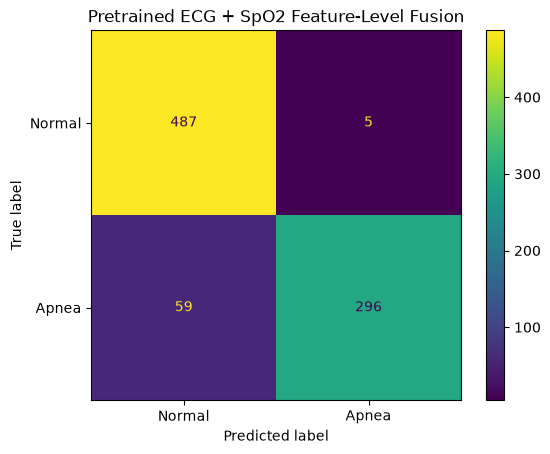

In [26]:
test_prob = fusion_model.predict(
    [X_ecg_test, X_spo2_test], verbose=0
).ravel()

# Use 0.5 as the initial fusion decision threshold.
# Do not tune this threshold on the test set.
fusion_threshold = 0.5
test_pred = (test_prob >= fusion_threshold).astype(int)

print("Accuracy:", accuracy_score(y_test.astype(int), test_pred))
if len(np.unique(y_test)) == 2:
    print("ROC-AUC:", roc_auc_score(y_test, test_prob))
else:
    print("ROC-AUC undefined: test set contains only one class.")

print(classification_report(
    y_test.astype(int), test_pred,
    labels=[0, 1],
    target_names=["Normal", "Apnea"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test.astype(int), test_pred,
    labels=[0, 1],
    display_labels=["Normal", "Apnea"]
)
plt.title("Pretrained ECG + SpO2 Feature-Level Fusion")
plt.show()

## 10. Save the fusion model and per-window predictions

The two original model files are loaded as inputs to this model. The saved fusion model contains the pretrained branch weights and the newly trained fusion head.

In [27]:
fusion_model_path = OUTPUT_DIR / "ecg_spo2_feature_fusion_pretrained_cnn.keras"
fusion_model.save(fusion_model_path)

prediction_df = test_df[["record", "minute", "label"]].copy()
prediction_df["fusion_probability"] = test_prob
prediction_df["fusion_prediction"] = test_pred
prediction_df["threshold"] = fusion_threshold
prediction_df.to_csv(
    OUTPUT_DIR / "feature_fusion_test_predictions.csv",
    index=False
)

summary = {
    "fusion_type": "intermediate_feature_level_fusion",
    "pretrained_ecg_model": str(ECG_MODEL_PATH),
    "pretrained_spo2_model": str(SPO2_MODEL_PATH),
    "feature_layer": "Dense(32) output before Dropout and sigmoid classifier",
    "pretrained_branches_frozen_initially": True,
    "fine_tuning_enabled": FINE_TUNE,
    "excluded_records": sorted(EXCLUDED_RECORDS),
    "train_records": sorted(TRAIN_RECORDS),
    "validation_records": sorted(VAL_RECORDS),
    "test_records": sorted(TEST_RECORDS),
    "paired_train_windows": int(len(train_df)),
    "paired_validation_windows": int(len(val_df)),
    "paired_test_windows": int(len(test_df)),
    "threshold": fusion_threshold,
    "spo2_normalization_mean": spo2_mean,
    "spo2_normalization_std": spo2_std
}
with open(OUTPUT_DIR / "feature_fusion_config.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Saved fusion model:", fusion_model_path)

Saved fusion model: C:\Users\navee\sleep-apnea-signal-analysis\results\fusion_model\ecg_spo2_feature_fusion_pretrained_cnn.keras


In [30]:
print("Fusion model inputs:")
print(fusion_model.input_shape)

print("\nFusion model outputs:")
print(fusion_model.output_shape)

fusion_model.summary()

Fusion model inputs:
[(None, 6000, 1), (None, 60, 1)]

Fusion model outputs:
(None, 1)


Model: "Pretrained_ECG_SpO2_Feature_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ ecg_input (InputLayer)        │ (None, 6000, 1)           │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ spo2_input (InputLayer)       │ (None, 60, 1)             │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ ecg_feature_extractor         │ (None, 32)                │          25,376 │ ecg_input[0][0]            │
│ (Functional)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ spo2_feature_extractor        │ (None, 16)                │           2,384 │ spo2_input[0][0]           │
│ (Functional)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ intermediate_feature_concate… │ (None, 48)                │               0 │ ecg_feature_extractor[0][… │
│ (Concatenate)                 │                           │                 │ spo2_feature_extractor[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fusion_dense_64 (Dense)       │ (None, 64)                │           3,136 │ intermediate_feature_conc… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fusion_dropout (Dropout)      │ (None, 64)                │               0 │ fusion_dense_64[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fusion_dense_32 (Dense)       │ (None, 32)                │           2,080 │ fusion_dropout[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ apnea_probability (Dense)     │ (None, 1)                 │              33 │ fusion_dense_32[0][0]      │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 43,509 (169.96 KB)

 Trainable params: 5,249 (20.50 KB)

 Non-trainable params: 27,760 (108.44 KB)

 Optimizer params: 10,500 (41.02 KB)

In [37]:

def predict_apnea(ecg_sample, spo2_sample, threshold=0.5):

    ecg_input = np.asarray(
        ecg_sample, dtype=np.float32
    ).reshape(1, 6000, 1)

    spo2_input = np.asarray(
        spo2_sample, dtype=np.float32
    ).reshape(1, 60, 1)

    probability = float(
        fusion_model.predict(
            {
                "ecg_input": ecg_input,
                "spo2_input": spo2_input
            },
            verbose=0
        )[0][0]
    )

    return {
        "Prediction": "Apnea" if probability >= threshold else "Normal",
        "Apnea Probability": round(probability, 4),
        "Threshold": threshold
    }


In [38]:

probabilities = fusion_model.predict(
    {
        "ecg_input": X_ecg_test[:10],
        "spo2_input": X_spo2_test[:10]
    },
    verbose=0
).flatten()

for i, probability in enumerate(probabilities):

    actual = "Apnea" if y_test[i] == 1 else "Normal"
    predicted = "Apnea" if probability >= 0.5 else "Normal"

    print(f"\nSample {i + 1}")
    print("Actual:", actual)
    print("Predicted:", predicted)
    print("Apnea probability:", round(float(probability), 4))



Sample 1
Actual: Normal
Predicted: Normal
Apnea probability: 0.005

Sample 2
Actual: Normal
Predicted: Normal
Apnea probability: 0.0028

Sample 3
Actual: Normal
Predicted: Normal
Apnea probability: 0.0558

Sample 4
Actual: Normal
Predicted: Normal
Apnea probability: 0.0022

Sample 5
Actual: Normal
Predicted: Normal
Apnea probability: 0.0399

Sample 6
Actual: Normal
Predicted: Normal
Apnea probability: 0.0011

Sample 7
Actual: Normal
Predicted: Normal
Apnea probability: 0.0016

Sample 8
Actual: Normal
Predicted: Apnea
Apnea probability: 0.9294

Sample 9
Actual: Normal
Predicted: Normal
Apnea probability: 0.0385

Sample 10
Actual: Normal
Predicted: Normal
Apnea probability: 0.0081


In [39]:

sample_index = 0

result = predict_apnea(
    X_ecg_test[sample_index],
    X_spo2_test[sample_index],
    threshold=0.5
)

print("Actual label:", "Apnea" if y_test[sample_index] == 1 else "Normal")
print("Model prediction:", result)


Actual label: Normal
Model prediction: {'Prediction': 'Normal', 'Apnea Probability': 0.005, 'Threshold': 0.5}


In [40]:

for i in range(10):
    result = predict_apnea(
        X_ecg_test[i],
        X_spo2_test[i],
        threshold=0.5
    )

    actual = "Apnea" if y_test[i] == 1 else "Normal"

    print(f"\nSample {i + 1}")
    print("Actual:", actual)
    print("Predicted:", result["Prediction"])
    print("Apnea probability:", result["Apnea Probability"])



Sample 1
Actual: Normal
Predicted: Normal
Apnea probability: 0.005

Sample 2
Actual: Normal
Predicted: Normal
Apnea probability: 0.0028

Sample 3
Actual: Normal
Predicted: Normal
Apnea probability: 0.0558

Sample 4
Actual: Normal
Predicted: Normal
Apnea probability: 0.0022

Sample 5
Actual: Normal
Predicted: Normal
Apnea probability: 0.0399

Sample 6
Actual: Normal
Predicted: Normal
Apnea probability: 0.0011

Sample 7
Actual: Normal
Predicted: Normal
Apnea probability: 0.0016

Sample 8
Actual: Normal
Predicted: Apnea
Apnea probability: 0.9294

Sample 9
Actual: Normal
Predicted: Normal
Apnea probability: 0.0385

Sample 10
Actual: Normal
Predicted: Normal
Apnea probability: 0.0081


In [41]:

# Select one test sample
sample_index = 0

# Get ECG and SpO2 signals
ecg_sample = X_ecg_test[sample_index]
spo2_sample = X_spo2_test[sample_index]

# Get prediction
result = predict_apnea(
    ecg_sample,
    spo2_sample,
    threshold=0.5
)

# Display results
actual = "Apnea" if y_test[sample_index] == 1 else "Normal"

print("=" * 40)
print("       SLEEP APNEA DETECTION")
print("=" * 40)

print("Sample number:", sample_index + 1)
print("Actual condition:", actual)
print("Predicted condition:", result["Prediction"])
print("Apnea probability:", f'{result["Apnea Probability"] * 100:.2f}%')

print("=" * 40)


       SLEEP APNEA DETECTION
Sample number: 1
Actual condition: Normal
Predicted condition: Normal
Apnea probability: 0.50%


In [42]:
import json
json.dump({
  "ecg":  [w.tolist() for w in ecg_model.get_weights()],
  "spo2": [w.tolist() for w in spo2_model.get_weights()],
  "head": [w.tolist() for n in ("fusion_dense_64","fusion_dense_32","apnea_probability")
           for w in fusion_model.get_layer(n).get_weights()]
}, open("weights.json", "w"))

## Important compatibility checks

- This notebook reuses the **actual trained weights** from `apnea_cnn.keras` and `spo2_cnn.keras`.
- It assumes the saved CNNs match the architectures in your earlier notebooks and expose a 32-unit Dense feature layer immediately before Dropout and the sigmoid output.
- ECG input must already be preprocessed exactly as it was for the ECG CNN: shape `(6000, 1)`.
- SpO₂ input must already be reduced to 60 one-second values. It is normalized using the mean and standard deviation saved in `spo2_model_config.json`, not newly estimated statistics.
- The pairing code assumes each SpO₂ `start_sample` is measured on the same 100 Hz minute grid used by the original preprocessing notebook. Check the paired record/minute counts carefully. If the metadata uses annotation-minute indices directly, export that field instead and join on it.
- Only paired patients can train the feature-fusion model. ECG-only records cannot be used as two-input examples.
- The test set has two independent patients. Window-level metrics alone can overstate generalization; report the number of test patients and windows.